### Estructura de la simulacion 

Clases:
- Location: Representa las ubicaciones (i.e para los transportistas / ordenes)
- Carrier: Modela a los transportistas
- Shipment: Modela las ordenes
- Simulation: Genera los carriers, genera las locaciones de las ordenes y grafica las soluciones
- LinearProgramming: Codigo necesasrio para resolver el problema con lp
- Matching: Codigo necesasrio para resolver el problema con matching

Realizado:
- Modelado de seleccionar al conductor mas cercano 
- Modelado de seleccionar al conductor con mas barato

Pendiente:
- Modelado de viajes compartidos
- Modelado de la vuelta de un transportista
- Modelado de la fecha de disponibilidad
- Modelado de la capacidad por viaje 
- Modelado de distancia que tiene que moverse para llegar a la orden el transportista

Obs:
- Cada transportista tiene 2/3 de probabilidad de estar disponible para relizar algun viaje

In [56]:
import random
from geopy.distance import geodesic
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np 
import uuid 
import openrouteservice
import time 
import pandas as pd

TRANSPORTISTAS = 150
VIAJES = 10
CARRIER_WILLING_KM_TO_MOVE = 10000 # cantidad de km que esta dispuesto a hacer hasta el punto de partida
N, M = TRANSPORTISTAS, VIAJES

OPEN_ROUTE_SERVICE_API_KEY = "eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImZlMzJjNjBkOGFiYzQwYTM4MGY3NDJiNDZlMzRkZWIxIiwiaCI6Im11cm11cjY0In0="
#"eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImY1ZTcyNTFjMWQ5ZDQwMjFhNjM1N2RjYzQ3NDMxZGRkIiwiaCI6Im11cm11cjY0In0="
OPEN_ROUTE_SERVICE_CLIENT = openrouteservice.Client(key=OPEN_ROUTE_SERVICE_API_KEY)
client = OPEN_ROUTE_SERVICE_CLIENT

class Location():
    cities_df = pd.read_csv('argentina_ciudades_coordenadas.csv')
    dist_df = pd.read_csv('distance_matrix.csv', index_col=0)
    
    def __init__(self):
        self.place, self.lat, self.lon = self.random_coordinates()
        
    def calculate_coordinates(self, address):
        try:
            geocode = client.pelias_search(text=address)
            coords = geocode['features'][0]['geometry']['coordinates']
            return coords[1], coords[0]  # (lat, lon)
        except Exception as e:
            print(f"Error al geocodificar {address}: {e}")
            return None

    @staticmethod
    def random_coordinates():
        try:
            random_row = Location.cities_df.sample(n=1).iloc[0]  # .iloc[0] es una Series (una fila)
            random_city = random_row['city']
            lat = float(random_row['lat'])
            lng = float(random_row['lng'])
            return random_city, lat, lng
        except:
            return Location.random_coordinates()

    def distance_to_point(self, city2):
        try:
            dist = Location.dist_df.at[self.place, city2]
            # Si dist es una Serie, agarramos el primer valor
            if isinstance(dist, pd.Series):
                dist = dist.iloc[0]
            return float(dist)
        except KeyError:
            print(f"Una o ambas ciudades '{self.place}' y '{city2}' no están en el archivo de distancias.")
            return 100_000.0


    def get_coordinates(self):
        return self.lat, self.lon
    
        
    def distance_to_point2(self, destination_cord) -> float:
        # Calculate the distance
        try:
            origin_cord = self.get_coordinates()[::-1]
            destination_cord = destination_cord[::-1]
            routes = client.directions(coordinates=[origin_cord, destination_cord], profile='driving-car')['routes']
            distance_in_meters = routes[0]['summary']['distance']
            distance_in_km = distance_in_meters / 1000
            return float("{:.2f}".format(distance_in_km))
        except Exception as e:
            print(f"Error origen {self.place} destination {destination_cord}, {e}")
            return 1_000_000

class Carrier():
    def __init__(self):
        self.id = str(uuid.uuid4())
        self.location = Location()
        self.available = bool(random.randint(0,2))
        self.km_cost = random.randint(2000, 3500) # se puede mejorar con datos de la pagina
        self.distance_to_start_assigned = []
    
    def get_coordinates(self):
        return self.location.get_coordinates()
    
    def get_km_cost(self):
        return self.km_cost

class Shipment():
    def __init__(self):
        self.id = str(uuid.uuid4())
        self.start = Location() 
        self.end = Location()
        self.distance = self.random_shipment()
        
    def random_shipment(self):
        while self.start == self.end:
            _, self.end = self.end.random_coordinates()
            time.sleep(1)
        
        distance = self.start.distance_to_point(self.end.place)
        return distance

    def get_start_coordinates(self):
        return self.start.get_coordinates()
    
    def get_end_coordinates(self):
        return self.end.get_coordinates()

class Simulation():
    def __init__(self):
        self.shipments = []
        self.available_carriers = []
        self.unavailable_carriers = []

    def init_sim(self):
        self.generate_carriers()
        self.generate_shipments()

    def generate_carriers(self):
        for _ in range(N):
            carrier = Carrier()
            if carrier.available:
                self.available_carriers.append(carrier)
            else:
                self.unavailable_carriers.append(carrier)
    
    def generate_shipments(self):
        for _ in range(M):
            shipment = Shipment()
            self.shipments.append(shipment)

    def available_carriers_coords(self) -> list:
        carriers_coords = []
        for carrier in self.available_carriers:
            carriers_coords.append(carrier.get_coordinates())
        return carriers_coords

    def unavailable_carriers_coords(self) -> list:
        carriers_coords = []
        for carrier in self.unavailable_carriers:
            carriers_coords.append(carrier.get_coordinates())
        return carriers_coords

    def start_shipments_coords(self) -> list:
        shipments = []
        for ship in self.shipments:
            shipments.append(ship.get_start_coordinates())
        return shipments

    def end_shipments_coords(self) -> list:
        shipments = []
        for ship in self.shipments:
            shipments.append(ship.get_end_coordinates())
        return shipments

    def shipments_coords(self) -> list:
        start = self.start_shipments_coords()
        end = self.end_shipments_coords()
        return [elem for pair in zip(start, end) for elem in pair]


    def show(self, solution):
        fig = plt.figure(figsize=(10, 8))
        ax = plt.axes(projection=ccrs.PlateCarree())

        ax.set_extent([-75, -52, -56, -20])  # Argentina
        ax.add_feature(cfeature.BORDERS)
        ax.add_feature(cfeature.COASTLINE)
        ax.add_feature(cfeature.LAND)

        it = 0
        # Agregar puntos
        for lat, lon in self.available_carriers_coords():
            if it == 0:
                ax.plot(lon, lat, marker='o', color='blue', markersize=5, alpha=0.6, label="Transportista disponible")
                it += 1
            else:
                ax.plot(lon, lat, marker='o', color='blue', markersize=5, alpha=0.6)
        
        for lat, lon in self.unavailable_carriers_coords():
            if it == 1:
                ax.plot(lon, lat, marker='o', color='red', markersize=5, alpha=0.6, label="Transportista no disponible")
                it += 1
            else:
                ax.plot(lon, lat, marker='o', color='red', markersize=5, alpha=0.6)

        # Aristas de los viajes
        coords = self.shipments_coords()  # lista de (lat, lon)
        for i in range(0, len(coords), 2):
            (lat1, lon1) = coords[i]       # origen
            (lat2, lon2) = coords[i + 1]   # destino

            # Dibujar la arista (línea) entre el origen y destino
            if it == 2:
                ax.plot([lon1, lon2], [lat1, lat2], linestyle='--', color='blue', linewidth=2)
                ax.plot(lon1, lat1, marker='s', color='green', markersize=8, label="Punto de partida")
                ax.plot(lon2, lat2, marker='o', color='orange', markersize=8, label="Punto de llegada")
                it += 1
            else:
                ax.plot([lon1, lon2], [lat1, lat2], linestyle='--', color='blue', linewidth=2)

                # Opcional: marcar los puntos si querés
                ax.plot(lon1, lat1, marker='s', color='green', markersize=8)
                ax.plot(lon2, lat2, marker='o', color='orange', markersize=8)

        coords = self.shipments_coords()
        for i in range(0, len(coords), 2):
            (lat1, lon1) = coords[i]
            (lat2, lon2) = coords[i + 1]
            if it == 3:
                ax.plot([lon1, lon2], [lat1, lat2], marker='.', color='purple', linewidth=2, alpha=0.8, label="Viajes")
                it += 1
            else:
                ax.plot([lon1, lon2], [lat1, lat2], marker='.', color='purple', linewidth=2, alpha=0.8)

        for i in range(0, len(solution), 2):
            (lat1, lon1) = solution[i]
            (lat2, lon2) = solution[i + 1]
            if it == 4:
                ax.plot([lon1, lon2], [lat1, lat2], marker='.', linestyle='--', color='black', linewidth=2, alpha=0.3, label="Soluciones")
                it += 1
            else:
                ax.plot([lon1, lon2], [lat1, lat2], marker='.', linestyle='--', color='black', linewidth=2, alpha=0.3)

        plt.legend()
        plt.title("Puntos y conexiones en Argentina")
        plt.show()

s = Simulation()
s.init_sim()


### Resumen

Tenemos $N$ transportistas y $M$ ordenes. 
- Generamos los costos por km de cada transportista de manera aleatoria 
- El punto de partida nunca es igual al punto de llagada de cada orden y son generadas de manera aleatoria
- La distancia estan pre-calculada (para no saturar a la api)

### Programacion Lineal (entera)

El resultado de aplicar programacion el algoritmo de pl usando linprog (metodo highs) nos devuelve una matriz. La cual si contiene un $1$ en la fila $i$, columna $j$, significa que el transportista $i$ realiza el viaje $j$ en modo que minimiza la distancia y el costo del viaje. 
El modelo esta codificado de la siguiente forma:

$$
\begin{align*}
\text{Minimizar} \quad 
& \sum_{i=1}^{N} \sum_{j=1}^{M} 
\left\{
\begin{array}{ll}
\left( \text{cost}_{ij} + \text{dist}_{ij} \right) \cdot x_{ij} & \text{si } (i,j) \text{ es viable} \\
0 & \text{si } (i,j) \text{ no es viable}
\end{array}
\right. \\[1.5ex]

\text{sujeto a} \quad 
& \sum_{i=1}^{N} x_{ij} = 1 \quad && \forall j \in \{1, \dots, M\} \quad \text{(cada orden es asignada)} \\
& \sum_{j=1}^{M} x_{ij} \leq 1 \quad && \forall i \in \{1, \dots, N\} \quad \text{(cada transportista hace a lo sumo un viaje)} \\
& x_{ij} \in \{0, 1\} \quad && \forall i,j \quad \text{(variable binaria)}
\end{align*}
$$




In [57]:
from scipy.optimize import linprog
import numpy as np
import time 
from sklearn.preprocessing import MinMaxScaler

class LinearProgramming():
    def __init__(self, carriers, shipments):
        self.available_carriers = carriers
        self.shipments = shipments
        self.N = len(self.available_carriers)
        self.M = len(self.shipments)
        self.x_ij = np.arange(self.N * self.M).reshape(self.N, self.M)
        self.computing_time = 0.0

    def transportista_realiza_viaje(self, carrier: Carrier, shipment: Shipment) -> bool:
        '''
        tener en cuenta:
            - disntancia que quiere moverse el transportista
            - la capacidad
            - la fecha
        '''
        if carrier.location.distance_to_point(shipment.start.place) < CARRIER_WILLING_KM_TO_MOVE:
            return True
        return False

    def get_travel_cost(self, carrier: Carrier, shipment: Shipment) -> int:
        return int(carrier.get_km_cost() * shipment.distance)

    def eq_restrictions(self,):
        # Restricción: Cada orden tiene que estar asignada
        A_eq = []  # Restricciones de igualdad
        b_eq = []  # Límite de cada restricción

        for j in range(self.M): 
            fila = [0] * (self.N * self.M)
            for i in range(self.N): 
                fila[i * self.M + j] = 1
            A_eq.append(fila)
            b_eq.append(1)
        return A_eq, b_eq
    
    def ub_restrictions(self):
        # Restricción: Cada transportista puede hacer a lo sumo un viaje
        A_ub = []  
        b_ub = []  

        for i in range(self.N):  
            fila = [0] * (self.N * self.M)
            for j in range(self.M): 
                fila[i * self.M + j] = 1 
            A_ub.append(fila)
            b_ub.append(1)
        return A_ub, b_ub

    def solve(self):
        alpha, beta, gamma = 1.0, 0.5, 0.3
        available_carriers = self.available_carriers
        shipments = self.shipments

        # Definir la función objetivo
        bounds = []
        for i, carrier in enumerate(available_carriers):
            for j, ship in enumerate(shipments):
                distance = carrier.location.distance_to_point(ship.start.place)
                is_viable = 1 #self.transportista_realiza_viaje(carrier=carrier, shipment=ship)
                
                if not is_viable:
                    bounds.append((0, 0))
                    self.x_ij[i,j] = 0
                else:
                    bounds.append((0, 1))
                    cost_norm = carrier.get_km_cost() * distance
                    dist_norm = distance
                    self.x_ij[i,j] = cost_norm + dist_norm

        print(self.x_ij)

        # Llamar a linprog usando el método "highs"
        c = self.x_ij.flatten()
        A_eq, b_eq = self.eq_restrictions()
        A_ub, b_ub = self.ub_restrictions()
        
        #bounds = self.bounds_restrictions(N=len(self.available_carriers), M=len(self.shipments))
        # print(A_eq, b_eq)
        # print(A_ub, b_ub)
        # print(bounds)
        self.computing_time = time.time()
        result = linprog(c, A_eq=A_eq, b_eq=b_eq, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs', options={"disp": True})
        self.computing_time = time.time() - self.computing_time

        print(f"Tiempo de computo {self.computing_time}")
        if result.success:
            carrier_ship = []
            print("Órdenes asignadas correctamente.")
            # Mostrar asignación de órdenes a transportistas
            for j in range(self.M):
                for i in range(self.N):
                    if result.x[i * self.M + j] > 0.5:  # Si la variable es 1 (significa que el transportista i realiza la orden j)
                        #print(f"Transportista {self.available_carriers[i].id} realiza la orden {self.shipments[j].id}")
                        #print(f"Distancia hasta start {self.available_carriers[i].distance_to_start_assigned[j]}")
                        carrier_ship.append(self.available_carriers[i])
                        carrier_ship.append(self.shipments[j])
            print(result.x)
            return carrier_ship
        else:
            print("No se pudo encontrar una solución.")  
            return None
        

lp = LinearProgramming(s.available_carriers, s.shipments)
solution = lp.solve()
print(solution)



[[3387186 1061799 3367280 2438216 2930802 4005189  234452 1209365  868062
   944675]
 [2770634 1250354 2347292 2025500 1804924 3137390  395476 1064342   29650
    79466]
 [3835942 1777961 3199160 2825925 2463704 4326132  615808 1487523   60082
    59037]
 [2865024  927125 2825058 2035974 2386244 3378461  144235 1041433  669551
   732673]
 [7570450 5492120 8121009 4698841 2455211 8398251 5037698 6226483 4844231
  4812629]
 [3074119 1363215 2462668 2512403 2565744 3468936  433955  890934  444610
   492153]
 [3257991 1601822 2647935 2414298 1974311 3643822  665676 1329021  207243
   154874]
 [3445028 1598411 2891495 2513524 2163064 3887539  563038 1361621   54082
    15562]
 [2949994 1141294 2771243 2000502 1974981 3421026  214404 1184252  350014
   400293]
 [2673133  907776 2724500 1683078 1834560 3159045  255154 1167322  559582
   605387]
 [2330774 1313904 3857635   69891 2129061 3040264 1922637 2411212 2274685
  2313686]
 [1982749  480992 3121103  828049 2270658 2636526 1228567 1613512

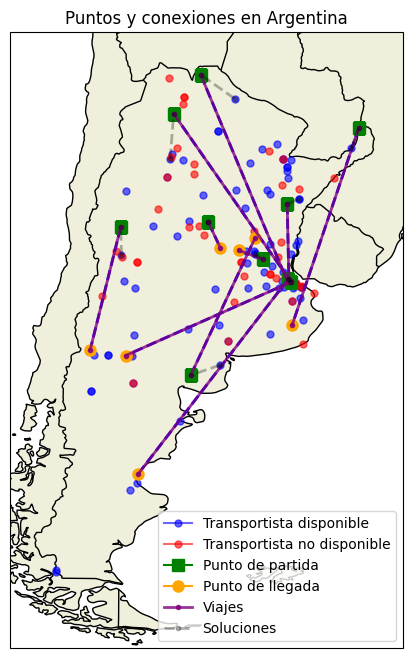

In [58]:

if solution:
    solution_match = []
    for i in range(0, len(solution), 2):
        solution_match.append(solution[i].get_coordinates())
        solution_match.append(solution[i+1].get_start_coordinates())
    s.show(solution_match)
else:
    no_solution = []
    s.show([])
            

### Matching

En caso de resolver el problema con matching, utilizamos la misma matriz contruida enteriormente ($x_ij$) y utilizamos el algoritmo **húngaro** (también conocido como **Kuhn-Munkres**), el cual devuelve la combinación que minimiza la suma de los costos.

In [59]:
from scipy.optimize import linear_sum_assignment

class Matching():
    def __init__(self, carriers, shipments):
        self.available_carriers = carriers
        self.shipments = shipments
        self.N = len(self.available_carriers)
        self.M = len(self.shipments)
        self.x_ij = np.arange(self.N * self.M).reshape(self.N, self.M)
        self.computing_time = 0.0

    def transportista_realiza_viaje(self, carrier: Carrier, shipment: Shipment) -> bool:
        '''
        tener en cuenta:
            - disntancia que quiere moverse el transportista
            - la capacidad
            - la fecha
        '''
        if carrier.location.distance_to_point(shipment.start.place) < CARRIER_WILLING_KM_TO_MOVE:
            return True
        return False

    def get_travel_cost(self, carrier: Carrier, shipment: Shipment) -> int:
        return int(carrier.get_km_cost() * shipment.distance)

    def scale_weights(self, weigth):
        scaler = MinMaxScaler()
        return scaler.fit_transform(weigth)

    def solve(self):
        alpha, beta, gamma = 1.0, 0.5, 0.3
        available_carriers = self.available_carriers
        shipments = self.shipments

        # Definir la función objetivo
        bounds = []
        for i, carrier in enumerate(available_carriers):
            for j, ship in enumerate(shipments):
                distance = carrier.location.distance_to_point(ship.start.place)
                carrier.distance_to_start_assigned.append(distance)
                is_viable = 1 #self.transportista_realiza_viaje(carrier=carrier, shipment=ship)
                
                if not is_viable:
                    self.x_ij[i,j] = 100_000_000_000_000
                else:
                    cost_norm = carrier.get_km_cost() * distance
                    dist_norm = distance
                    self.x_ij[i,j] = cost_norm + dist_norm

        print(self.x_ij)

        self.computing_time = time.time()
        row_ind, col_ind = linear_sum_assignment(self.x_ij)
        self.computing_time = time.time() - self.computing_time

        total_cost = self.x_ij[row_ind, col_ind].sum()
        carrier_ship = []
        for t, o in zip(row_ind, col_ind):
            print(f"  Transportista {t} → Orden {o} (costo: {self.x_ij[t][o]})")
            #print(f"Distancia hasta start {self.available_carriers[i].distance_to_start_assigned[j]}")
            carrier_ship.append(self.available_carriers[t])
            carrier_ship.append(self.shipments[o])
            print("--- " * 4)
        print(f"Costo total mínimo: {total_cost}")
        print(f"Tiempo de computo {self.computing_time}")
        return carrier_ship


mc = Matching(s.available_carriers, s.shipments)
mc_solution = mc.solve()
print(mc_solution)



[[3387186 1061799 3367280 2438216 2930802 4005189  234452 1209365  868062
   944675]
 [2770634 1250354 2347292 2025500 1804924 3137390  395476 1064342   29650
    79466]
 [3835942 1777961 3199160 2825925 2463704 4326132  615808 1487523   60082
    59037]
 [2865024  927125 2825058 2035974 2386244 3378461  144235 1041433  669551
   732673]
 [7570450 5492120 8121009 4698841 2455211 8398251 5037698 6226483 4844231
  4812629]
 [3074119 1363215 2462668 2512403 2565744 3468936  433955  890934  444610
   492153]
 [3257991 1601822 2647935 2414298 1974311 3643822  665676 1329021  207243
   154874]
 [3445028 1598411 2891495 2513524 2163064 3887539  563038 1361621   54082
    15562]
 [2949994 1141294 2771243 2000502 1974981 3421026  214404 1184252  350014
   400293]
 [2673133  907776 2724500 1683078 1834560 3159045  255154 1167322  559582
   605387]
 [2330774 1313904 3857635   69891 2129061 3040264 1922637 2411212 2274685
  2313686]
 [1982749  480992 3121103  828049 2270658 2636526 1228567 1613512

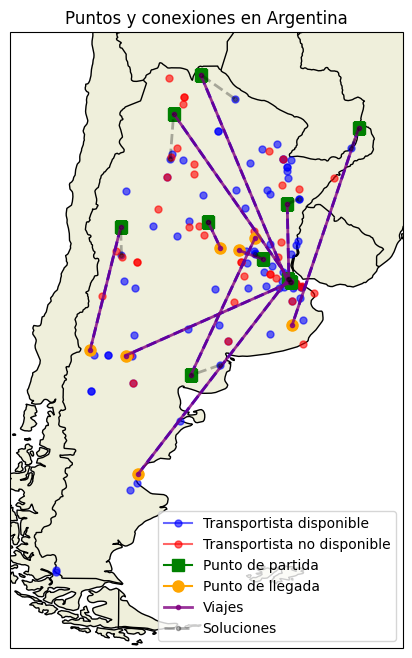

In [60]:
mc_solution_match = []
for i in range(0, len(mc_solution), 2):
    mc_solution_match.append(mc_solution[i].get_coordinates())
    mc_solution_match.append(mc_solution[i+1].get_start_coordinates())
s.show(mc_solution_match)
            